In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")


In [2]:
df = pd.read_csv('../data/pm.csv')

In [3]:
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [4]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [5]:
df.isna().sum()

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

In [90]:
df.isnull().sum()

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

In [12]:
df.shape

(10000, 14)

In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
failure_columns = ['Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']

for col in failure_columns:
    print(f"\n{col}")
    print(df[col].value_counts())
    print(df[col].value_counts(normalize=True) * 100)


Machine failure
Machine failure
0    9661
1     339
Name: count, dtype: int64
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64

TWF
TWF
0    9954
1      46
Name: count, dtype: int64
TWF
0    99.54
1     0.46
Name: proportion, dtype: float64

HDF
HDF
0    9885
1     115
Name: count, dtype: int64
HDF
0    98.85
1     1.15
Name: proportion, dtype: float64

PWF
PWF
0    9905
1      95
Name: count, dtype: int64
PWF
0    99.05
1     0.95
Name: proportion, dtype: float64

OSF
OSF
0    9902
1      98
Name: count, dtype: int64
OSF
0    99.02
1     0.98
Name: proportion, dtype: float64

RNF
RNF
0    9981
1      19
Name: count, dtype: int64
RNF
0    99.81
1     0.19
Name: proportion, dtype: float64


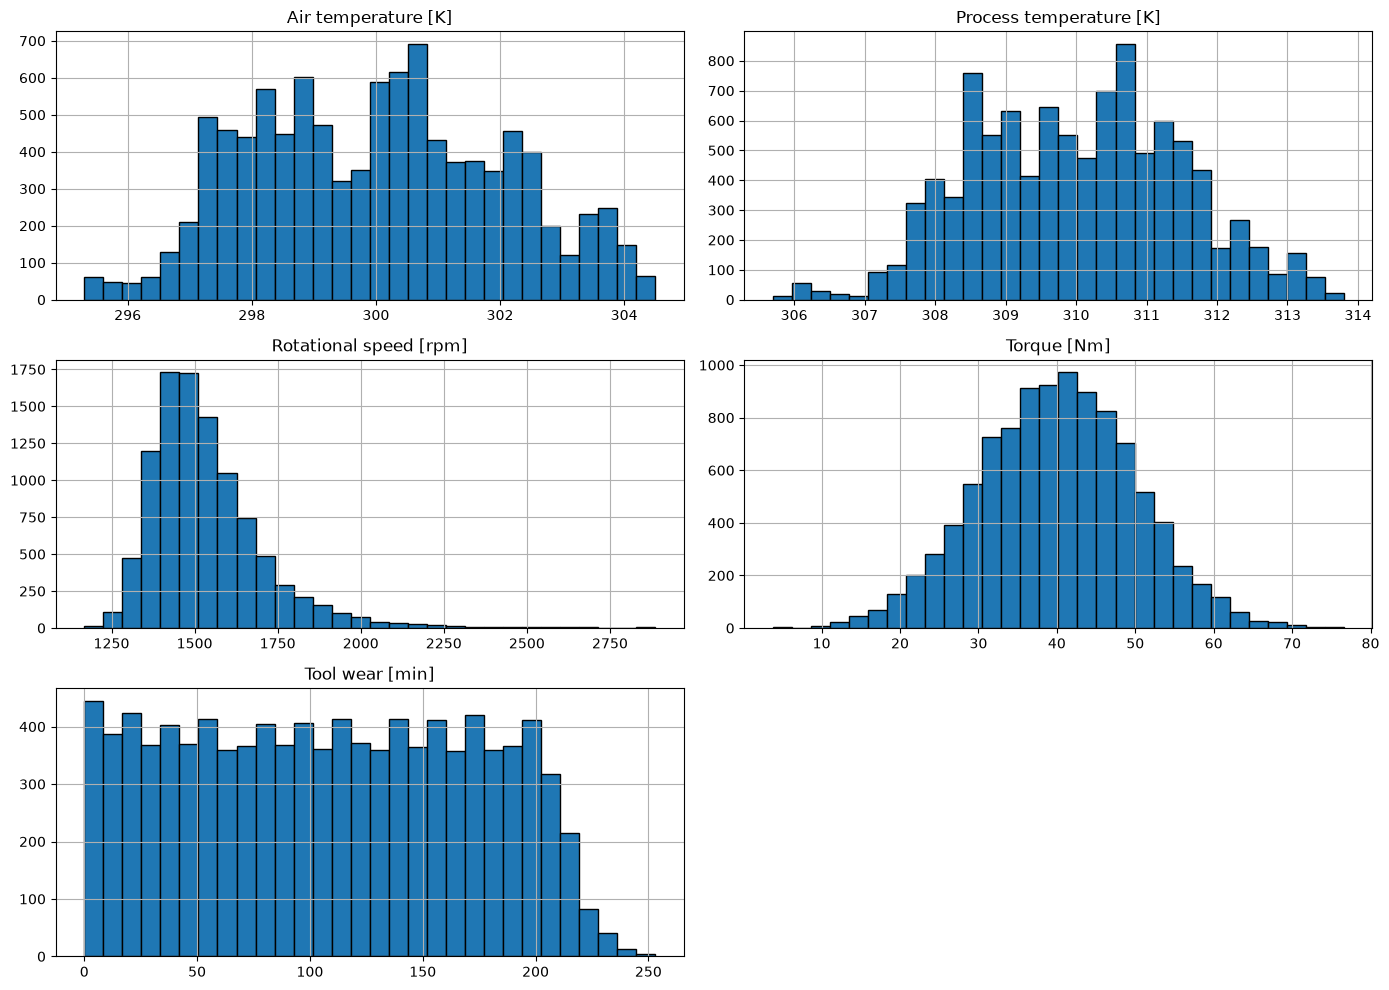

In [15]:
numerical_columns = [
    'Air temperature [K]',
    'Process temperature [K]',
    'Rotational speed [rpm]',
    'Torque [Nm]',
    'Tool wear [min]'
]

df[numerical_columns].hist(
    figsize=(14, 10),
    bins=30,
    edgecolor='black'
)

plt.tight_layout()
plt.show()

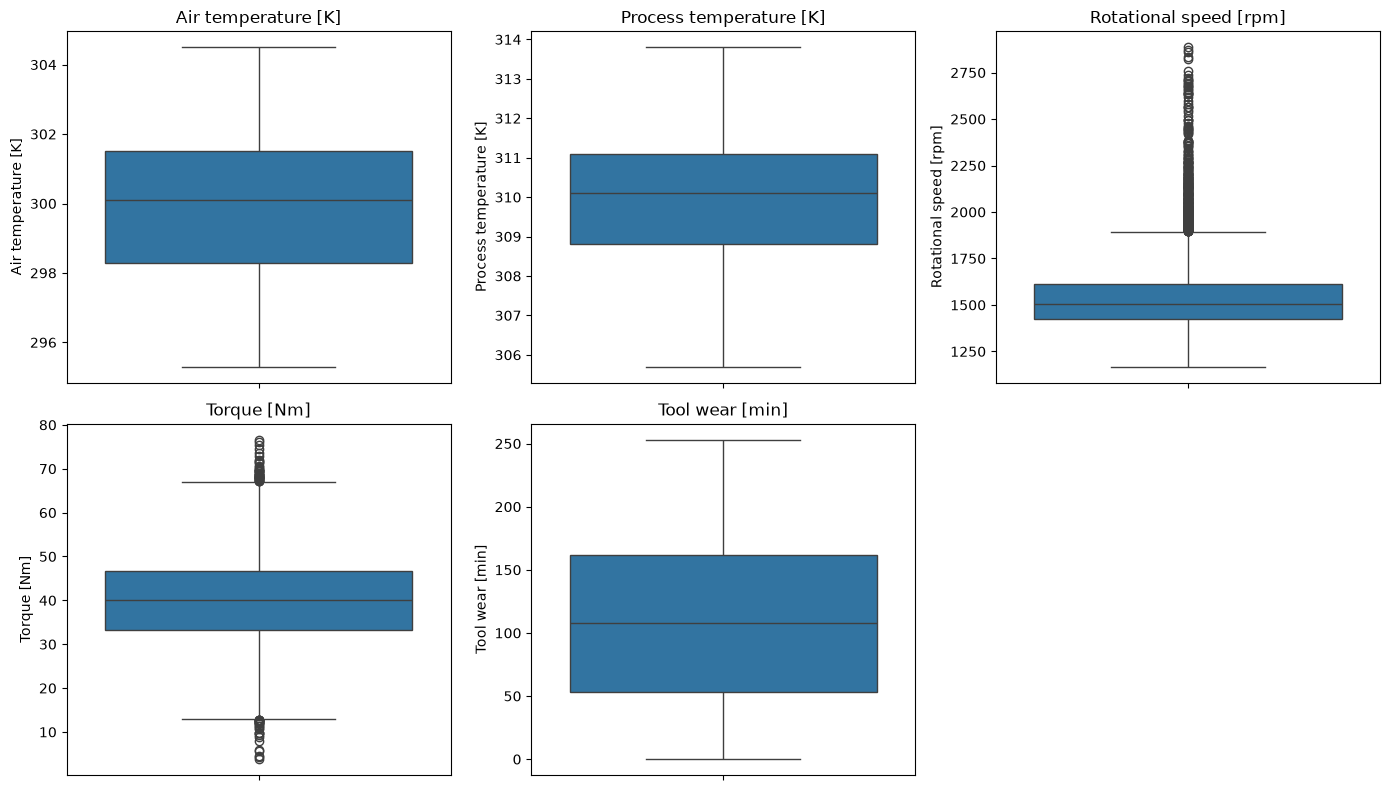

In [16]:
plt.figure(figsize=(14, 8))

for i, col in enumerate(numerical_columns, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

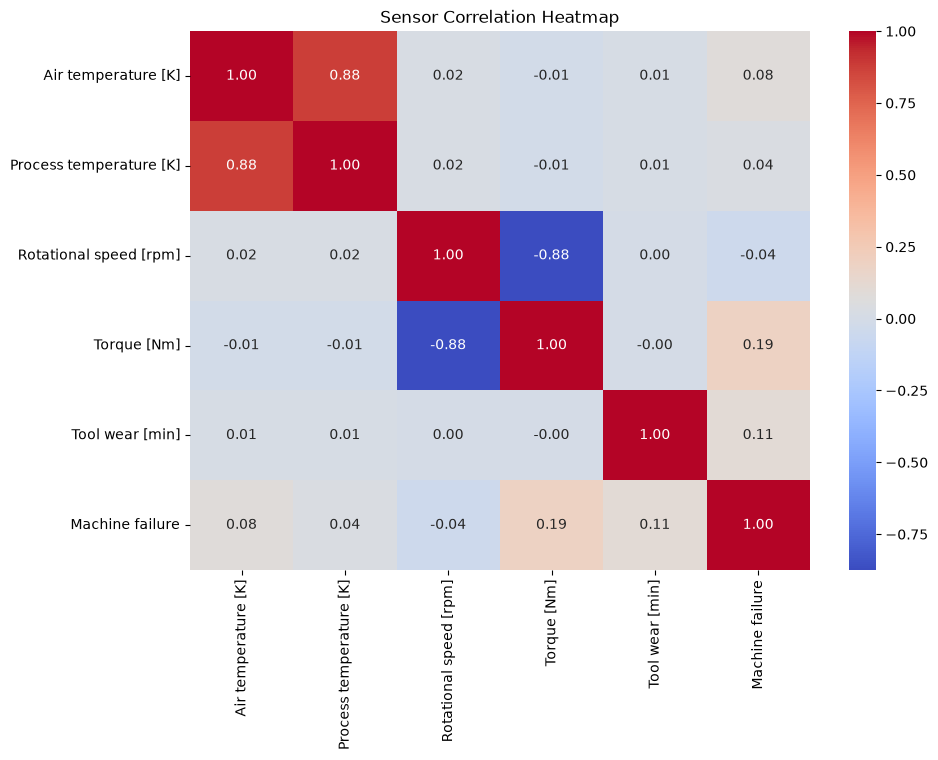

In [17]:
plt.figure(figsize=(10, 7))

correlation = df[numerical_columns + ['Machine failure']].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Sensor Correlation Heatmap')
plt.show()

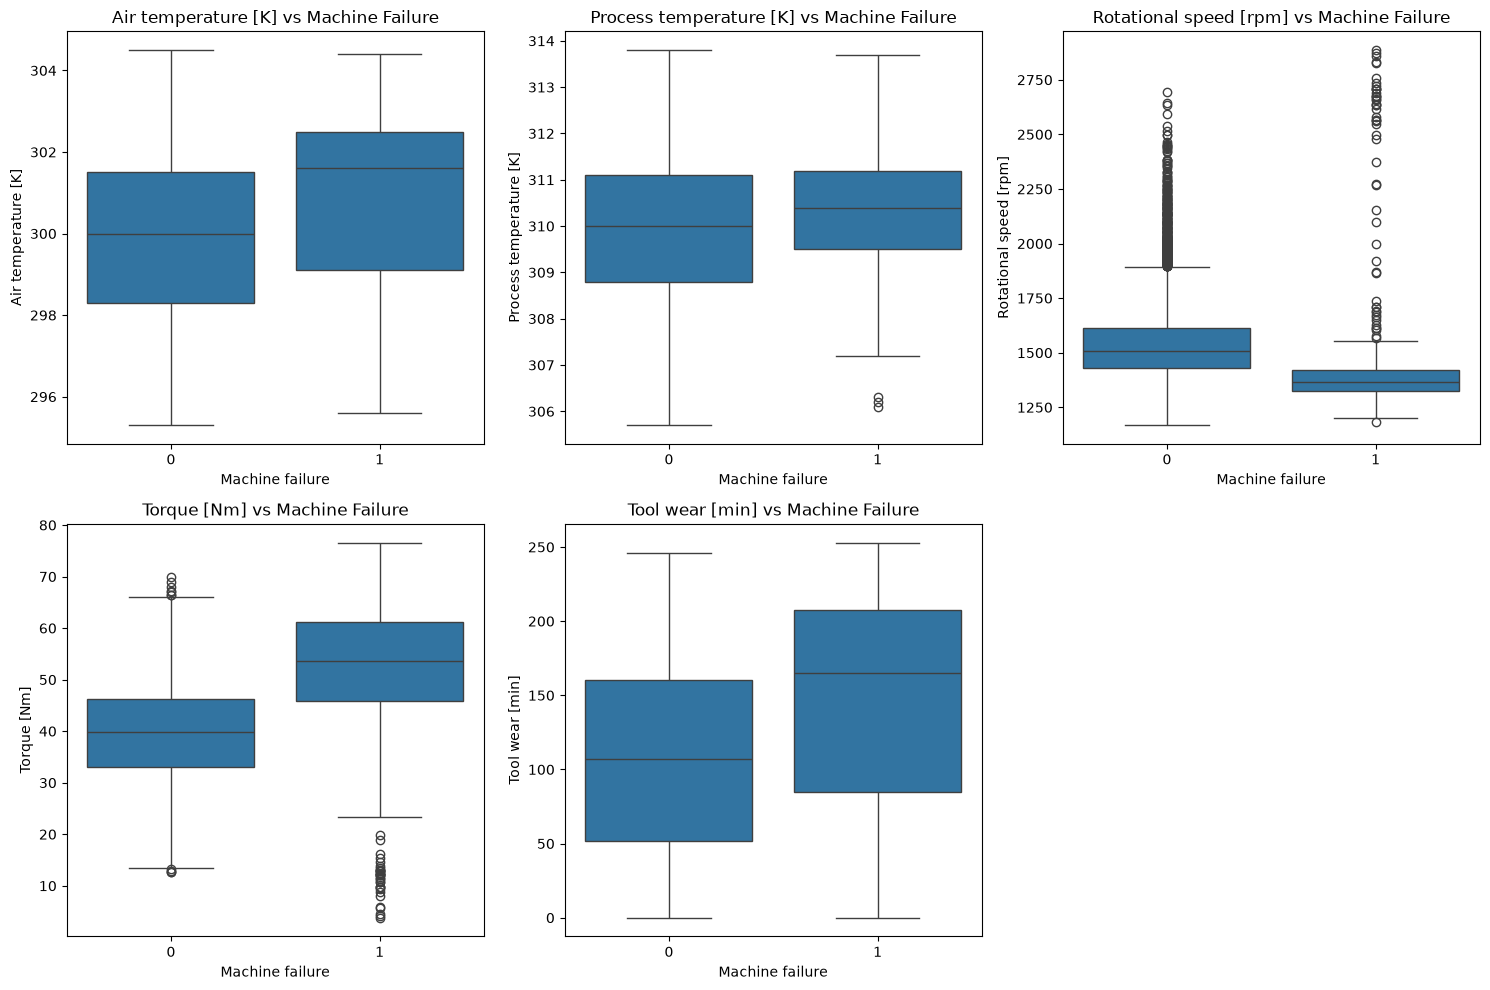

In [18]:
plt.figure(figsize=(15, 10))

for i, col in enumerate(numerical_columns, 1):

    plt.subplot(2, 3, i)

    sns.boxplot(
        data=df,
        x='Machine failure',
        y=col
    )

    plt.title(f'{col} vs Machine Failure')

plt.tight_layout()
plt.show()

In [19]:
failure_analysis = df.groupby('Machine failure')[
    numerical_columns
].agg(['mean', 'median', 'std'])

print(failure_analysis.T)

Machine failure                           0            1
Air temperature [K]     mean     299.973999   300.886431
                        median   300.000000   301.600000
                        std        1.990748     2.071473
Process temperature [K] mean     309.995570   310.290265
                        median   310.000000   310.400000
                        std        1.486846     1.363686
Rotational speed [rpm]  mean    1540.260014  1496.486726
                        median  1507.000000  1365.000000
                        std      167.394734   384.943547
Torque [Nm]             mean      39.629655    50.168142
                        median    39.900000    53.700000
                        std        9.472080    16.374498
Tool wear [min]         mean     106.693717   143.781711
                        median   107.000000   165.000000
                        std       62.945790    72.759876


In [20]:
comparison = df.groupby('Machine failure')[
    numerical_columns
].mean().T

comparison.columns = ['Normal', 'Failed']

comparison['Difference (%)'] = (
    (comparison['Failed'] - comparison['Normal'])
    / comparison['Normal']
) * 100

print(comparison.round(3))

#We want to quantify how much each sensor variable changes between normal and failed machines.

                           Normal    Failed  Difference (%)
Air temperature [K]       299.974   300.886           0.304
Process temperature [K]   309.996   310.290           0.095
Rotational speed [rpm]   1540.260  1496.487          -2.842
Torque [Nm]                39.630    50.168          26.592
Tool wear [min]           106.694   143.782          34.761


In [21]:
pd.crosstab(
    df['Type'],
    df['Machine failure'],
    normalize='index'
) * 100

Machine failure,0,1
Type,,
H,97.906281,2.093719
L,96.083333,3.916667
M,97.230564,2.769436


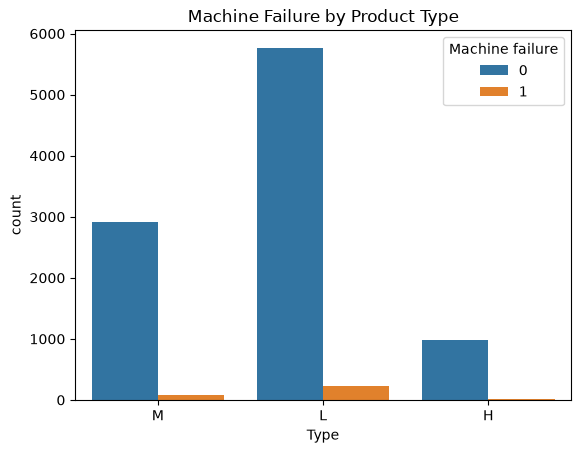

In [22]:
sns.countplot(
    data=df,
    x='Type',
    hue='Machine failure'
)

plt.title('Machine Failure by Product Type')
plt.show()

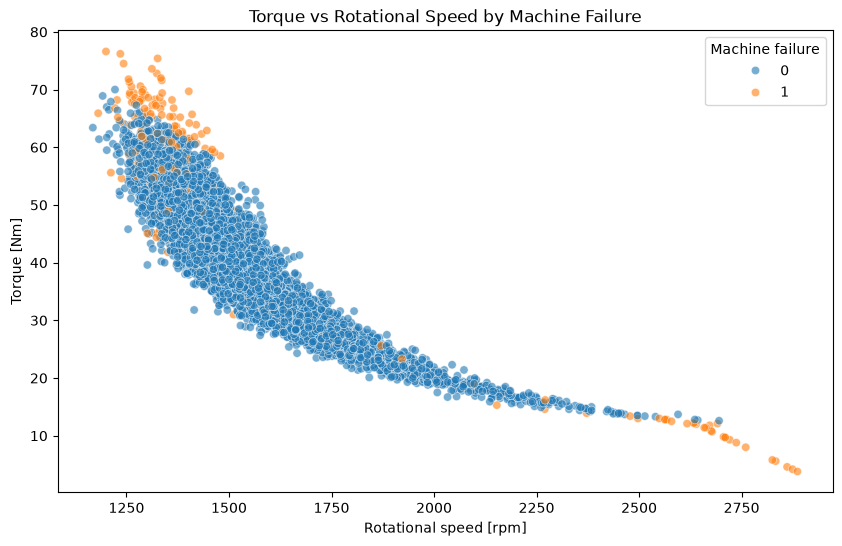

In [23]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Rotational speed [rpm]',
    y='Torque [Nm]',
    hue='Machine failure',
    alpha=0.6
)

plt.title('Torque vs Rotational Speed by Machine Failure')
plt.show()

#This will help us visually investigate whether combinations of these two variables distinguish failed machines.

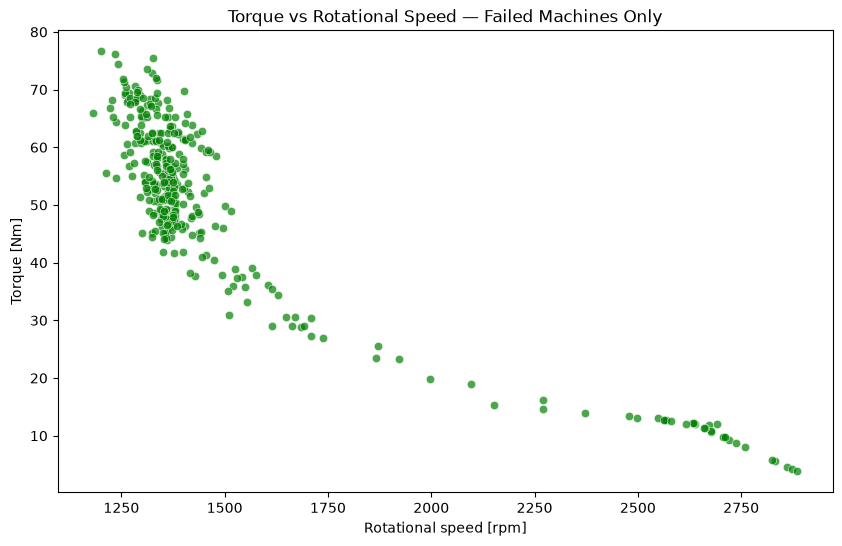

In [24]:
failed_machines = df[df['Machine failure'] == 1]

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=failed_machines,
    x='Rotational speed [rpm]',
    y='Torque [Nm]',
    color='green',
    alpha=0.7
)

plt.title('Torque vs Rotational Speed — Failed Machines Only')
plt.show()

In [25]:
X = df.drop(columns=[
    'UDI',
    'Product ID',
    'Machine failure',
    'TWF',
    'HDF',
    'PWF',
    'OSF',
    'RNF'
])

y = df['Machine failure']

print(X.head())
print("Shape:", X.shape)

  Type  Air temperature [K]  Process temperature [K]  Rotational speed [rpm]  \
0    M                298.1                    308.6                    1551   
1    L                298.2                    308.7                    1408   
2    L                298.1                    308.5                    1498   
3    L                298.2                    308.6                    1433   
4    L                298.2                    308.7                    1408   

   Torque [Nm]  Tool wear [min]  
0         42.8                0  
1         46.3                3  
2         49.4                5  
3         39.5                7  
4         40.0                9  
Shape: (10000, 6)


In [79]:
from sklearn.model_selection import train_test_split

# First split: 70% training, 30% remaining
X_train_new, X_remaining, y_train_new, y_remaining = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

# Second split: divide remaining data equally
X_val_new, X_test_new, y_val_new, y_test_new = train_test_split(
    X_remaining,
    y_remaining,
    test_size=0.50,
    stratify=y_remaining,
    random_state=42
)

print("Training set:", X_train_new.shape)
print("Validation set:", X_val_new.shape)
print("Test set:", X_test_new.shape)

print("\nFailure distribution:")

print("Training:")
print(y_train_new.value_counts(normalize=True))

print("\nValidation:")
print(y_val_new.value_counts(normalize=True))

print("\nTest:")
print(y_test_new.value_counts(normalize=True))

Training set: (7000, 6)
Validation set: (1500, 6)
Test set: (1500, 6)

Failure distribution:
Training:
Machine failure
0    0.966143
1    0.033857
Name: proportion, dtype: float64

Validation:
Machine failure
0    0.966
1    0.034
Name: proportion, dtype: float64

Test:
Machine failure
0    0.966
1    0.034
Name: proportion, dtype: float64


In [81]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Identify numerical and categorical columns
numerical_features = X_train_new.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train_new.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

# Preprocessing
preprocessor_new = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

# Complete ML pipeline
rf_pipeline_new = Pipeline(
    steps=[
        ("preprocessor", preprocessor_new),
        ("classifier", RandomForestClassifier(random_state=42))
    ]
)

# Hyperparameter search
param_grid_new = {
    "classifier__n_estimators": [300, 500],
    "classifier__max_depth": [10, 20, None],
    "classifier__min_samples_split": [2, 5],
    "classifier__min_samples_leaf": [1, 2],
    "classifier__class_weight": [None, "balanced_subsample"]
}

cv_new = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search_new = GridSearchCV(
    estimator=rf_pipeline_new,
    param_grid=param_grid_new,
    scoring="average_precision",
    cv=cv_new,
    n_jobs=-1,
    verbose=1
)

# Train using training data ONLY
grid_search_new.fit(X_train_new, y_train_new)

best_rf_new = grid_search_new.best_estimator_

print("\nBest parameters:")
print(grid_search_new.best_params_)

print("\nBest cross-validation Average Precision:")
print(grid_search_new.best_score_)

Numerical features: ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
Categorical features: ['Type']
Fitting 5 folds for each of 48 candidates, totalling 240 fits

Best parameters:
{'classifier__class_weight': None, 'classifier__max_depth': 20, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 500}

Best cross-validation Average Precision:
0.7648202050567594


In [83]:
from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score
)

# Get failure probabilities from the validation dataset
y_val_prob = best_rf_new.predict_proba(X_val_new)[:, 1]

# Calculate precision-recall values
precision, recall, thresholds = precision_recall_curve(
    y_val_new,
    y_val_prob
)

# Find thresholds that achieve at least 80% recall
valid_indices = np.where(recall[:-1] >= 0.80)[0]

if len(valid_indices) == 0:
    print("No threshold achieves 80% recall.")

else:
    # Select the threshold with the highest precision
    best_index = valid_indices[
        np.argmax(precision[valid_indices])
    ]

    best_threshold_new = thresholds[best_index]

    # Make predictions using selected threshold
    y_val_pred = (
        y_val_prob >= best_threshold_new
    ).astype(int)

    print("Selected threshold:", best_threshold_new)
    print("Validation Precision:",
          precision_score(y_val_new, y_val_pred))
    print("Validation Recall:",
          recall_score(y_val_new, y_val_pred))
    print("Validation F1:",
          f1_score(y_val_new, y_val_pred))

Selected threshold: 0.23421825396825396
Validation Precision: 0.6507936507936508
Validation Recall: 0.803921568627451
Validation F1: 0.7192982456140351


FINAL TEST RESULTS
--------------------------
Threshold: 0.23421825396825396
Accuracy: 0.9766666666666667
Precision: 0.6212121212121212
Recall: 0.803921568627451
F1 Score: 0.7008547008547008
Average Precision: 0.779114049074669
ROC-AUC: 0.9681795423483404

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.98      0.99      1449
           1       0.62      0.80      0.70        51

    accuracy                           0.98      1500
   macro avg       0.81      0.89      0.84      1500
weighted avg       0.98      0.98      0.98      1500



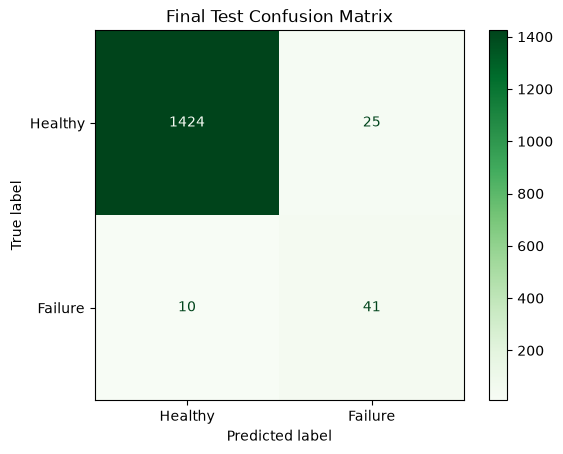

In [84]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# 1. Predict probabilities on untouched test data
y_test_prob = best_rf_new.predict_proba(X_test_new)[:, 1]

# 2. Apply the threshold selected on validation data
y_test_pred = (
    y_test_prob >= best_threshold_new
).astype(int)

# 3. Calculate evaluation metrics
print("FINAL TEST RESULTS")
print("--------------------------")

print("Threshold:", best_threshold_new)
print("Accuracy:", accuracy_score(y_test_new, y_test_pred))
print("Precision:", precision_score(y_test_new, y_test_pred))
print("Recall:", recall_score(y_test_new, y_test_pred))
print("F1 Score:", f1_score(y_test_new, y_test_pred))
print("Average Precision:", average_precision_score(y_test_new, y_test_prob))
print("ROC-AUC:", roc_auc_score(y_test_new, y_test_prob))

# 4. Classification report
print("\nClassification Report:")
print(classification_report(y_test_new, y_test_pred))

# 5. Confusion matrix
cm = confusion_matrix(y_test_new, y_test_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Healthy", "Failure"]
)

disp.plot(cmap="Greens")
plt.title("Final Test Confusion Matrix")
plt.show()

                        Feature  Importance
3              num__Torque [Nm]    0.344588
2   num__Rotational speed [rpm]    0.242309
4          num__Tool wear [min]    0.163531
0      num__Air temperature [K]    0.113378
1  num__Process temperature [K]    0.111867
6                   cat__Type_L    0.011117
7                   cat__Type_M    0.007873
5                   cat__Type_H    0.005337


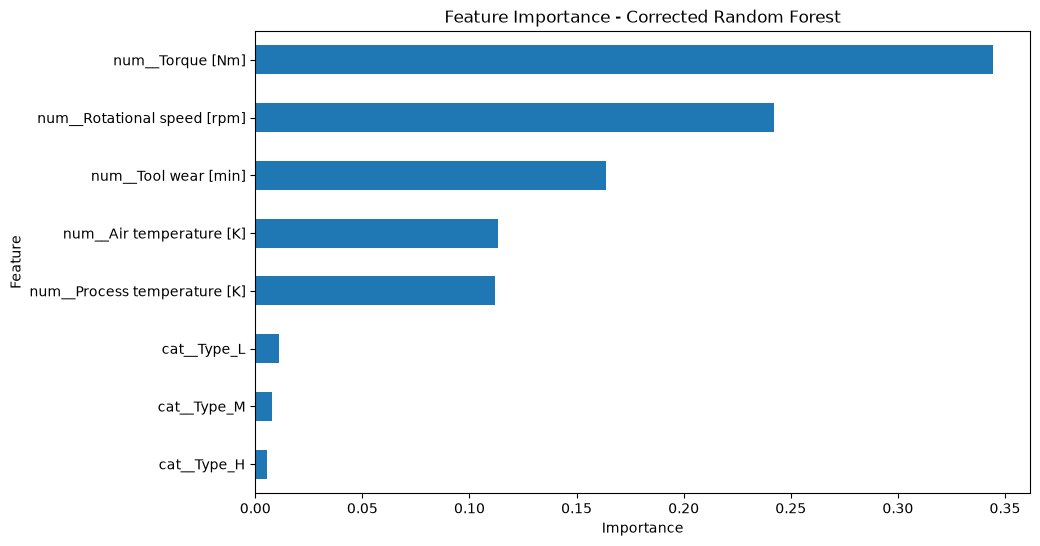

In [85]:
# Extract the fitted Random Forest
rf_classifier_new = best_rf_new.named_steps["classifier"]

# Get transformed feature names
feature_names_new = best_rf_new.named_steps[
    "preprocessor"
].get_feature_names_out()

# Extract feature importance
importance_df_new = pd.DataFrame({
    "Feature": feature_names_new,
    "Importance": rf_classifier_new.feature_importances_
})

importance_df_new = importance_df_new.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df_new)

# Visualize
importance_df_new.plot(
    x="Feature",
    y="Importance",
    kind="barh",
    figsize=(10, 6),
    legend=False
)

plt.title("Feature Importance - Corrected Random Forest")
plt.xlabel("Importance")
plt.gca().invert_yaxis()
plt.show()

In [86]:
import shap

# Extract fitted preprocessing and classifier
preprocessor_new = best_rf_new.named_steps["preprocessor"]
rf_classifier_new = best_rf_new.named_steps["classifier"]

# Transform validation data
X_val_transformed = preprocessor_new.transform(X_val_new)

# Convert sparse matrix if necessary
if hasattr(X_val_transformed, "toarray"):
    X_val_transformed = X_val_transformed.toarray()

# Get transformed feature names
feature_names_new = preprocessor_new.get_feature_names_out()

# Create SHAP explainer
explainer_new = shap.TreeExplainer(rf_classifier_new)

# Calculate SHAP values
shap_values_new = explainer_new.shap_values(
    X_val_transformed
)

# Handle class 1 (machine failure)
if isinstance(shap_values_new, list):
    failure_shap_new = shap_values_new[1]
else:
    shap_array_new = np.asarray(shap_values_new)

    if shap_array_new.ndim == 3:
        failure_shap_new = shap_array_new[:, :, 1]
    else:
        failure_shap_new = shap_array_new

print("SHAP shape:", failure_shap_new.shape)
print("Feature names:", feature_names_new)

SHAP shape: (1500, 8)
Feature names: ['num__Air temperature [K]' 'num__Process temperature [K]'
 'num__Rotational speed [rpm]' 'num__Torque [Nm]' 'num__Tool wear [min]'
 'cat__Type_H' 'cat__Type_L' 'cat__Type_M']


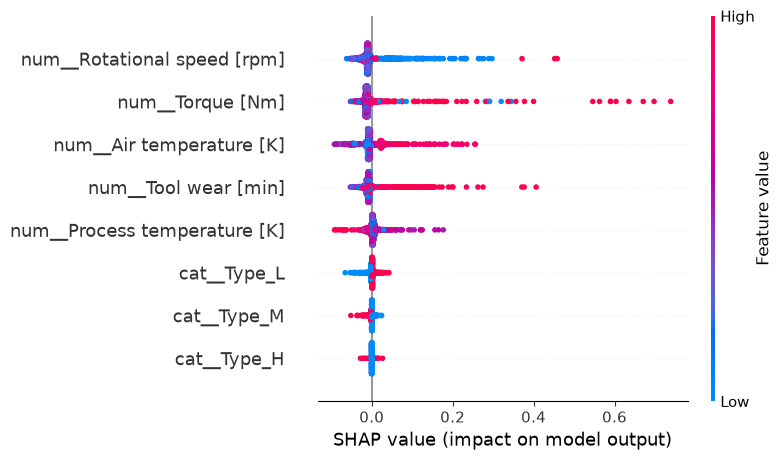

In [87]:
shap.summary_plot(
    failure_shap_new,
    X_val_transformed,
    feature_names=feature_names_new
)

In [82]:
numerical_features = X.select_dtypes(
    include=['number']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object', 'category']
).columns.tolist()

print("Numerical:", numerical_features)
print("Categorical:", categorical_features)

Numerical: ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
Categorical: ['Type']


In [27]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [28]:
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nTraining distribution:")
print(y_train.value_counts())

print("\nTesting distribution:")
print(y_test.value_counts())

Training shape: (8000, 6)
Testing shape: (2000, 6)

Training distribution:
Machine failure
0    7729
1     271
Name: count, dtype: int64

Testing distribution:
Machine failure
0    1932
1      68
Name: count, dtype: int64


In [29]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),

        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

In [30]:
# Fit on training data and transform
X_train_processed = preprocessor.fit_transform(X_train)

# Only transform test data
X_test_processed = preprocessor.transform(X_test)

print("Training shape:", X_train_processed.shape)
print("Testing shape:", X_test_processed.shape)

Training shape: (8000, 8)
Testing shape: (2000, 8)


In [31]:
feature_names = preprocessor.get_feature_names_out()

print(feature_names)

['num__Air temperature [K]' 'num__Process temperature [K]'
 'num__Rotational speed [rpm]' 'num__Torque [Nm]' 'num__Tool wear [min]'
 'cat__Type_H' 'cat__Type_L' 'cat__Type_M']


In [32]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

In [33]:
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['Type','Air temperature [K]','Process temperature [K]', 'Rotational speed [rpm]','Torque [Nm]','Tool wear [min]']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).B

In [34]:
y_pred = model.predict(X_test)

y_prob = model.predict_proba(X_test)[:, 1]

In [35]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    average_precision_score
)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("PR-AUC:", average_precision_score(y_test, y_prob))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.9675
Precision: 0.6363636363636364
Recall: 0.10294117647058823
F1 Score: 0.17721518987341772
PR-AUC: 0.4205369579251732

Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.98      1932
           1       0.64      0.10      0.18        68

    accuracy                           0.97      2000
   macro avg       0.80      0.55      0.58      2000
weighted avg       0.96      0.97      0.96      2000


Confusion Matrix:
[[1928    4]
 [  61    7]]


In [36]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

weighted_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        class_weight='balanced',
        max_iter=1000
    ))
])

In [37]:
weighted_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['Type','Air temperature [K]','Process temperature [K]', 'Rotational speed [rpm]','Torque [Nm]','Tool wear [min]']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).B

In [38]:
y_pred_weighted = weighted_model.predict(X_test)

y_prob_weighted = weighted_model.predict_proba(X_test)[:, 1]

In [39]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

print("Accuracy:", accuracy_score(y_test, y_pred_weighted))
print("Precision:", precision_score(y_test, y_pred_weighted))
print("Recall:", recall_score(y_test, y_pred_weighted))
print("F1 Score:", f1_score(y_test, y_pred_weighted))

print("PR-AUC:", average_precision_score(
    y_test, y_prob_weighted
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_weighted))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_weighted))

Accuracy: 0.8245
Precision: 0.14177215189873418
Recall: 0.8235294117647058
F1 Score: 0.24190064794816415
PR-AUC: 0.38176196610560775

Confusion Matrix:
[[1593  339]
 [  12   56]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.82      0.90      1932
           1       0.14      0.82      0.24        68

    accuracy                           0.82      2000
   macro avg       0.57      0.82      0.57      2000
weighted avg       0.96      0.82      0.88      2000



In [40]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

thresholds = [0.2, 0.3, 0.4, 0.5, 0.6]

for threshold in thresholds:

    predictions = (
        y_prob_weighted >= threshold
    ).astype(int)

    print(f"\nThreshold: {threshold}")

    print("Precision:", precision_score(
        y_test, predictions
    ))

    print("Recall:", recall_score(
        y_test, predictions
    ))

    print("F1:", f1_score(
        y_test, predictions
    ))


Threshold: 0.2
Precision: 0.07246376811594203
Recall: 0.9558823529411765
F1: 0.13471502590673576

Threshold: 0.3
Precision: 0.09197080291970802
Recall: 0.9264705882352942
F1: 0.16733067729083664

Threshold: 0.4
Precision: 0.11509433962264151
Recall: 0.8970588235294118
F1: 0.2040133779264214

Threshold: 0.5
Precision: 0.14177215189873418
Recall: 0.8235294117647058
F1: 0.24190064794816415

Threshold: 0.6
Precision: 0.18309859154929578
Recall: 0.7647058823529411
F1: 0.29545454545454547


In [41]:
X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

In [42]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

rf_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=300,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

In [43]:
rf_model.fit(X_train_sub, y_train_sub)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['Type','Air temperature [K]','Process temperature [K]', 'Rotational speed [rpm]','Torque [Nm]','Tool wear [min]']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).B

In [44]:
y_val_prob = rf_model.predict_proba(X_val)[:, 1]

y_val_pred = (y_val_prob >= 0.5).astype(int)

In [45]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score
)

print(classification_report(y_val, y_val_pred))
print(confusion_matrix(y_val, y_val_pred))
print("PR-AUC:", average_precision_score(y_val, y_val_prob))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1546
           1       0.65      0.65      0.65        54

    accuracy                           0.98      1600
   macro avg       0.82      0.82      0.82      1600
weighted avg       0.98      0.98      0.98      1600

[[1527   19]
 [  19   35]]
PR-AUC: 0.706732139318484


In [46]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    accuracy_score
)

models = {
    'Logistic Regression': Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', LogisticRegression(max_iter=1000))
    ]),

    'Weighted Logistic Regression': Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', LogisticRegression(
            class_weight='balanced',
            max_iter=1000
        ))
    ]),

    'Random Forest': Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', RandomForestClassifier(
            n_estimators=300,
            class_weight='balanced',
            random_state=42,
            n_jobs=-1
        ))
    ])
}

results = []

for name, model in models.items():

    model.fit(X_train_sub, y_train_sub)

    predictions = model.predict(X_val)
    probabilities = model.predict_proba(X_val)[:, 1]

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_val, predictions),
        'Precision': precision_score(y_val, predictions),
        'Recall': recall_score(y_val, predictions),
        'F1': f1_score(y_val, predictions),
        'PR_AUC': average_precision_score(y_val, probabilities)
    })

results_df = pd.DataFrame(results)

print(results_df.round(4))

                          Model  Accuracy  Precision  Recall      F1  PR_AUC
0           Logistic Regression    0.9719     0.8000  0.2222  0.3478  0.4574
1  Weighted Logistic Regression    0.8231     0.1433  0.8519  0.2453  0.4197
2                 Random Forest    0.9762     0.6481  0.6481  0.6481  0.7067


In [47]:
# Extract trained Random Forest
rf_classifier = rf_model.named_steps['classifier']

# Get feature names after preprocessing
feature_names = (
    rf_model.named_steps['preprocessor']
    .get_feature_names_out()
)

# Extract feature importance
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_classifier.feature_importances_
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

print(importance_df)

                        Feature  Importance
3              num__Torque [Nm]    0.304392
2   num__Rotational speed [rpm]    0.301511
4          num__Tool wear [min]    0.192068
0      num__Air temperature [K]    0.110521
1  num__Process temperature [K]    0.074135
6                   cat__Type_L    0.007270
7                   cat__Type_M    0.005829
5                   cat__Type_H    0.004275


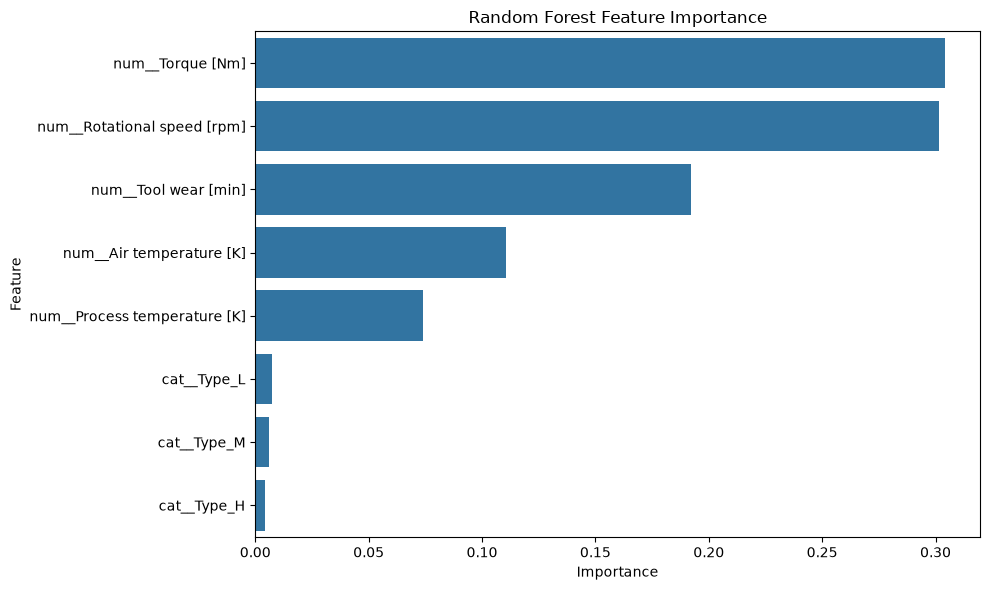

In [48]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df,
    x='Importance',
    y='Feature'
)

plt.title('Random Forest Feature Importance')
plt.tight_layout()
plt.show()

In [49]:
from sklearn.metrics import precision_recall_curve
import numpy as np

precision, recall, thresholds = precision_recall_curve(
    y_val,
    y_val_prob
)

threshold_results = pd.DataFrame({
    'Threshold': thresholds,
    'Precision': precision[:-1],
    'Recall': recall[:-1]
})

# Keep thresholds with at least 80% recall
eligible = threshold_results[
    threshold_results['Recall'] >= 0.80
]

print(
    eligible.sort_values(
        'Precision',
        ascending=False
    ).head(10)
)

    Threshold  Precision    Recall
69   0.243333   0.411215  0.814815
68   0.240000   0.407407  0.814815
67   0.236667   0.400000  0.814815
66   0.233333   0.396396  0.814815
65   0.230000   0.385965  0.814815
64   0.226667   0.379310  0.814815
63   0.223333   0.376068  0.814815
62   0.220000   0.363636  0.814815
60   0.210000   0.362903  0.833333
61   0.213333   0.360656  0.814815


In [50]:
from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(
    y_val,
    y_val_prob
)

threshold_results = pd.DataFrame({
    'Threshold': thresholds,
    'Precision': precision[:-1],
    'Recall': recall[:-1]
})

eligible = threshold_results[
    threshold_results['Recall'] >= 0.80
]

print(
    eligible.sort_values(
        by='Precision',
        ascending=False
    ).head(10)
)

    Threshold  Precision    Recall
69   0.243333   0.411215  0.814815
68   0.240000   0.407407  0.814815
67   0.236667   0.400000  0.814815
66   0.233333   0.396396  0.814815
65   0.230000   0.385965  0.814815
64   0.226667   0.379310  0.814815
63   0.223333   0.376068  0.814815
62   0.220000   0.363636  0.814815
60   0.210000   0.362903  0.833333
61   0.213333   0.360656  0.814815


In [51]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

rf_pipeline = Pipeline([
    ('preprocessor', clone(preprocessor)),
    ('classifier', RandomForestClassifier(
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

In [52]:
param_grid = {
    'classifier__n_estimators': [200, 300, 500],
    'classifier__max_depth': [None, 10, 20],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4]
}

In [53]:
grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    scoring='average_precision',
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best CV PR-AUC:", grid_search.best_score_)

Fitting 5 folds for each of 81 candidates, totalling 405 fits
Best Parameters: {'classifier__max_depth': 20, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 500}
Best CV PR-AUC: 0.74157508687172


In [54]:
best_rf = grid_search.best_estimator_

print(best_rf)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Air temperature [K]',
                                                   'Process temperature [K]',
                                                   'Rotational speed [rpm]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Type'])])),
                ('classifier',
                 RandomForestClassifier(class_weight='balanced', max_depth=20,
                                        n_estimators=500, n_jobs=-1,
                                        random_state=42))])


In [55]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    accuracy_score
)

y_test_pred = best_rf.predict(X_test)
y_test_prob = best_rf.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_test_pred))

print(
    "Average Precision:",
    average_precision_score(y_test, y_test_prob)
)

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

Accuracy: 0.98
Average Precision: 0.7572583728346827

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1932
           1       0.73      0.66      0.69        68

    accuracy                           0.98      2000
   macro avg       0.86      0.83      0.84      2000
weighted avg       0.98      0.98      0.98      2000


Confusion Matrix:
[[1915   17]
 [  23   45]]


In [56]:
from sklearn.metrics import precision_recall_curve

# Get probabilities from the tuned model
y_val_prob_tuned = best_rf.predict_proba(X_val)[:, 1]

precision, recall, thresholds = precision_recall_curve(
    y_val,
    y_val_prob_tuned
)

threshold_df = pd.DataFrame({
    'Threshold': thresholds,
    'Precision': precision[:-1],
    'Recall': recall[:-1]
})

# Require at least 80% recall
eligible = threshold_df[threshold_df['Recall'] >= 0.80]

print(
    eligible.sort_values(
        'Precision',
        ascending=False
    ).head(10)
)

     Threshold  Precision    Recall
180   0.999684        1.0  0.814815
175   0.999091        1.0  0.907407
170   0.994966        1.0  1.000000
172   0.998457        1.0  0.962963
173   0.998891        1.0  0.944444
174   0.998958        1.0  0.925926
171   0.997897        1.0  0.981481
176   0.999274        1.0  0.888889
177   0.999357        1.0  0.870370
178   0.999436        1.0  0.851852


In [57]:
from sklearn.metrics import precision_recall_curve

# Get probabilities from the tuned model
y_val_prob_tuned = best_rf.predict_proba(X_val)[:, 1]

precision, recall, thresholds = precision_recall_curve(
    y_val,
    y_val_prob_tuned
)

threshold_df = pd.DataFrame({
    'Threshold': thresholds,
    'Precision': precision[:-1],
    'Recall': recall[:-1]
})

# Require at least 80% recall
eligible = threshold_df[threshold_df['Recall'] >= 0.80]

print(
    eligible.sort_values(
        'Precision',
        ascending=False
    ).head(10)
)

     Threshold  Precision    Recall
180   0.999684        1.0  0.814815
175   0.999091        1.0  0.907407
170   0.994966        1.0  1.000000
172   0.998457        1.0  0.962963
173   0.998891        1.0  0.944444
174   0.998958        1.0  0.925926
171   0.997897        1.0  0.981481
176   0.999274        1.0  0.888889
177   0.999357        1.0  0.870370
178   0.999436        1.0  0.851852


In [58]:
# Actual failure probabilities
failed_probabilities = y_val_prob_tuned[y_val == 1]

# Actual healthy probabilities
healthy_probabilities = y_val_prob_tuned[y_val == 0]

print("Failed machine probabilities:")
print(pd.Series(failed_probabilities).describe())

print("\nHealthy machine probabilities:")
print(pd.Series(healthy_probabilities).describe())

print("\nHighest healthy probability:",
      healthy_probabilities.max())

print("\nLowest failure probability:",
      failed_probabilities.min())

Failed machine probabilities:
count    54.000000
mean      0.999698
std       0.000780
min       0.994966
25%       0.999781
50%       1.000000
75%       1.000000
max       1.000000
dtype: float64

Healthy machine probabilities:
count    1546.000000
mean        0.019080
std         0.052286
min         0.000000
25%         0.000000
50%         0.000000
75%         0.008000
max         0.447519
dtype: float64

Highest healthy probability: 0.4475193598108782

Lowest failure probability: 0.9949659063426333


In [59]:
print("Features used by model:")
print(X.columns.tolist())

print("\nTarget:")
print(y.name)

Features used by model:
['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']

Target:
Machine failure


In [60]:
print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))
print("Test rows:", len(X_test))

print("\nValidation failure distribution:")
print(y_val.value_counts())

Training rows: 8000
Validation rows: 1600
Test rows: 2000

Validation failure distribution:
Machine failure
0    1546
1      54
Name: count, dtype: int64


In [61]:
print(
    "Training-validation overlap:",
    len(set(X_train_sub.index) & set(X_val.index))
)

print(
    "Training-test overlap:",
    len(set(X_train.index) & set(X_test.index))
)

print(
    "Validation-test overlap:",
    len(set(X_val.index) & set(X_test.index))
)

Training-validation overlap: 0
Training-test overlap: 0
Validation-test overlap: 0


In [62]:
from sklearn.inspection import permutation_importance

In [63]:
perm_result = permutation_importance(
    best_rf,
    X_val,
    y_val,
    scoring='average_precision',
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

In [64]:
permutation_df = pd.DataFrame({
    'Feature': X_val.columns,
    'Importance': perm_result.importances_mean,
    'Std': perm_result.importances_std
})

permutation_df = permutation_df.sort_values(
    by='Importance',
    ascending=False
)

print(permutation_df)

                   Feature  Importance       Std
4              Torque [Nm]    0.517020  0.044172
3   Rotational speed [rpm]    0.353443  0.040846
5          Tool wear [min]    0.290105  0.024312
1      Air temperature [K]    0.183592  0.022763
2  Process temperature [K]    0.081346  0.022810
0                     Type    0.056299  0.018991


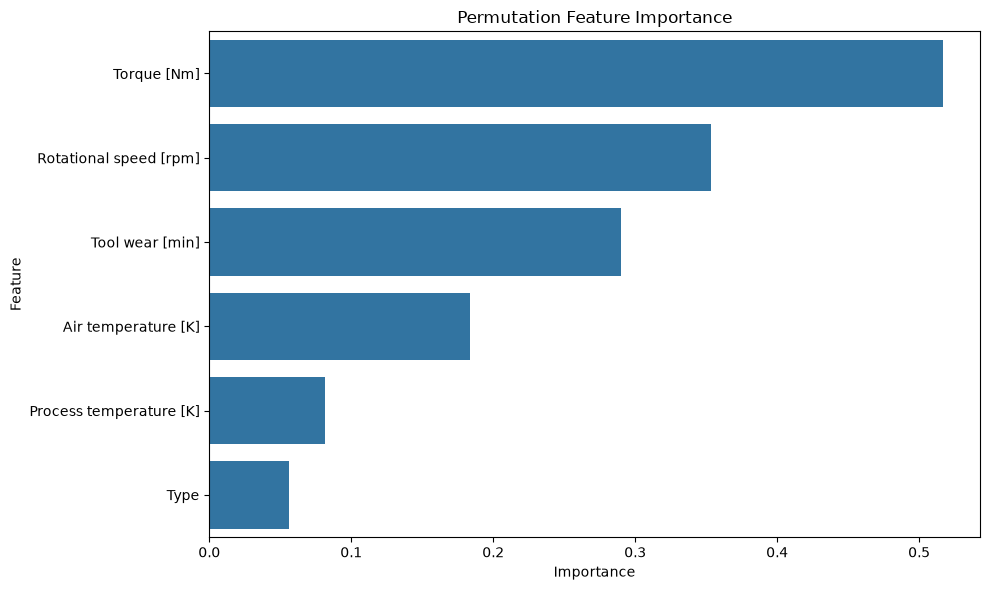

In [65]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=permutation_df,
    x='Importance',
    y='Feature'
)

plt.title('Permutation Feature Importance')
plt.tight_layout()
plt.show()

In [66]:
print(permutation_df.to_string(index=False))

                Feature  Importance      Std
            Torque [Nm]    0.517020 0.044172
 Rotational speed [rpm]    0.353443 0.040846
        Tool wear [min]    0.290105 0.024312
    Air temperature [K]    0.183592 0.022763
Process temperature [K]    0.081346 0.022810
                   Type    0.056299 0.018991


In [67]:
import shap

# Extract the trained Random Forest classifier
rf_classifier = best_rf.named_steps['classifier']

# Transform validation data
X_val_transformed = (
    best_rf.named_steps['preprocessor']
    .transform(X_val)
)

# Get transformed feature names
feature_names = (
    best_rf.named_steps['preprocessor']
    .get_feature_names_out()
)

# Create SHAP explainer
explainer = shap.TreeExplainer(rf_classifier)

# Calculate SHAP values
shap_values = explainer.shap_values(X_val_transformed)

print(type(shap_values))

<class 'numpy.ndarray'>


In [68]:
print("SHAP shape:", shap_values.shape)

print("Validation transformed shape:",
      X_val_transformed.shape)

print("Number of features:", len(feature_names))

SHAP shape: (1600, 8, 2)
Validation transformed shape: (1600, 8)
Number of features: 8


In [69]:
print(shap_values.ndim)

3


In [70]:
failure_shap = shap_values[:, :, 1]

print("Failure SHAP shape:", failure_shap.shape)

Failure SHAP shape: (1600, 8)


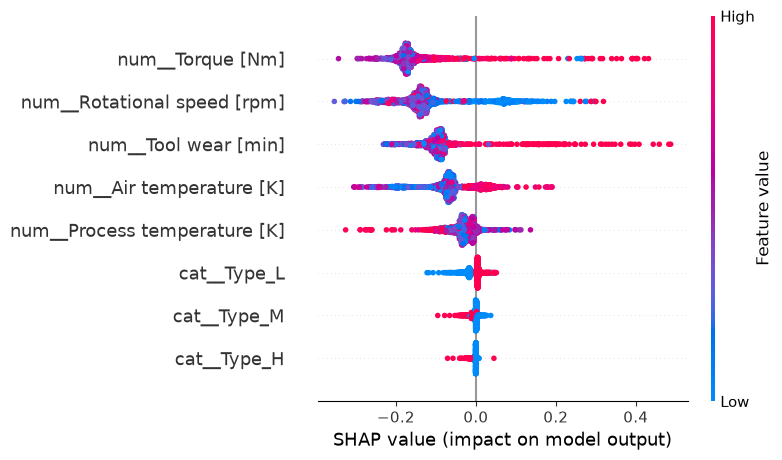

In [71]:
shap.summary_plot(
    failure_shap,
    X_val_transformed,
    feature_names=feature_names
)

In [72]:
import numpy as np

# Find validation rows where the actual label is failure
failed_indices = np.where(y_val.values == 1)[0]

# Select the first failed machine
sample_idx = failed_indices[0]

print("Sample index:", sample_idx)
print("Actual failure:", y_val.iloc[sample_idx])
print("Predicted probability:",
      y_val_prob_tuned[sample_idx])

Sample index: 5
Actual failure: 1
Predicted probability: 0.9999750000000001


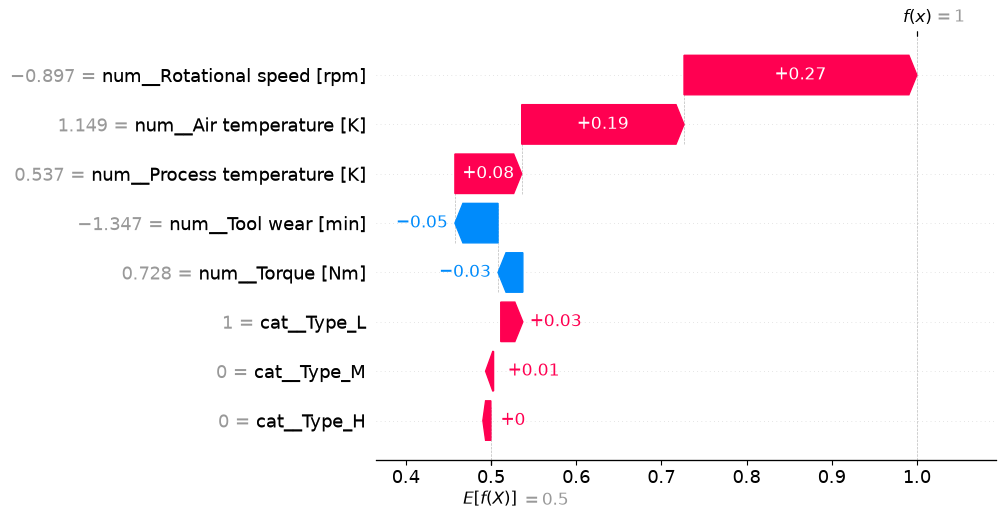

In [73]:
shap.plots.waterfall(
    shap.Explanation(
        values=failure_shap[sample_idx],
        base_values=explainer.expected_value[1],
        data=X_val_transformed[sample_idx],
        feature_names=feature_names
    )
)

In [76]:
import joblib
import os

os.makedirs("../models", exist_ok=True)

model_path = "../models/predictive_maintenance_model.joblib"

joblib.dump(best_rf, model_path)

print("Model saved successfully!")
print("File size:", os.path.getsize(model_path), "bytes")

Model saved successfully!
File size: 18646018 bytes


In [77]:
loaded_model = joblib.load(
    "../models/predictive_maintenance_model.joblib"
)

print("Model loaded successfully!")

Model loaded successfully!


In [78]:
# Select one sample from the test dataset
sample = X_test.iloc[[0]]

# Predict machine failure
prediction = loaded_model.predict(sample)[0]

# Get failure probability
probability = loaded_model.predict_proba(sample)[0][1]

print("Predicted result:", prediction)
print("Failure probability:", round(probability * 100, 2), "%")

Predicted result: 0
Failure probability: 33.2 %


In [88]:
import joblib
import json
from pathlib import Path

BASE_DIR = Path.cwd()

if BASE_DIR.name == "notebook":
    BASE_DIR = BASE_DIR.parent

MODEL_DIR = BASE_DIR / "models"
MODEL_DIR.mkdir(exist_ok=True)

# Save corrected model
joblib.dump(
    best_rf_new,
    MODEL_DIR / "predictive_maintenance_model.joblib"
)

# Save selected threshold
with open(MODEL_DIR / "threshold.json", "w") as file:
    json.dump(
        {"threshold": 0.23421825396825396},
        file,
        indent=4
    )

print("Corrected model and threshold saved successfully!")

Corrected model and threshold saved successfully!


In [89]:
from pathlib import Path
import joblib

# Locate the project root
BASE_DIR = Path.cwd()

if BASE_DIR.name == "notebook":
    BASE_DIR = BASE_DIR.parent

MODEL_PATH = BASE_DIR / "models" / "predictive_maintenance_model.joblib"

# Save the corrected, retrained pipeline
joblib.dump(best_rf_new, MODEL_PATH)

print("Model saved:", MODEL_PATH)
print("File size:", MODEL_PATH.stat().st_size, "bytes")

# Verify that it can be loaded
test_model = joblib.load(MODEL_PATH)

print("Model loaded successfully!")

Model saved: /Users/faiza/Desktop/predictive/models/predictive_maintenance_model.joblib
File size: 10894434 bytes
Model loaded successfully!
